# 08 Priority Cutoff Sensitivity

This notebook tests whether the conclusion that district priorities are weight-sensitive depends on selecting the top 10% as the policy-priority threshold.

It uses the verified reconstructed DFSI baseline and the saved Monte Carlo weight vectors from the **moderate uncertainty scenario**. The Monte Carlo experiment is not resampled: the saved moderate-scenario weights are replayed against the same 709 complete one-to-one district records so that alternative priority cutoffs can be evaluated reproducibly.

The 0.20 and 0.80 probability thresholds are descriptive analytical reporting thresholds, not universal policy standards.

## Setup

All paths are resolved with `pathlib` from the repository root. The notebook reads `data/processed` and `outputs/tables` inputs and writes only new audit tables and figures under `outputs`. No file in `data/raw` is modified.

In [1]:
from pathlib import Path
import hashlib
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 80)

NOTEBOOK_PATH = Path.cwd()
PROJECT_ROOT = NOTEBOOK_PATH if (NOTEBOOK_PATH / "data").exists() else NOTEBOOK_PATH.parent
BASELINE_PATH = PROJECT_ROOT / "data" / "processed" / "dfsi_verified_baseline.csv"
MC_DISTRICT_PATH = PROJECT_ROOT / "outputs" / "tables" / "dfsi_monte_carlo_district_uncertainty.csv"
MC_WEIGHTS_PATH = PROJECT_ROOT / "outputs" / "tables" / "dfsi_monte_carlo_sampled_weights.csv"
RAW_DIR = PROJECT_ROOT / "data" / "raw"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

CUT_OFFS = {
    "top_5pct": 36,
    "top_10pct": 71,
    "top_15pct": 106,
    "top_20pct": 142,
    "top_25pct": 177,
}
EXPECTED_CUTOFF_COUNTS = [36, 71, 106, 142, 177]
EXPECTED_DISTRICTS = 709
BASELINE_WEIGHTS = np.array([1.0, 1.0, 2.0, 1.0, 1.0, 1.0], dtype="float64")
TERM_COLUMNS = [
    "u_events",
    "u_duration",
    "u_fatalities",
    "u_injured",
    "u_flooded_area",
    "u_population",
]


def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

RAW_HASHES_BEFORE = {path.name: sha256_file(path) for path in sorted(RAW_DIR.glob("*.csv"))}
print(f"Project root: {PROJECT_ROOT}")
print(f"Baseline input: {BASELINE_PATH.relative_to(PROJECT_ROOT)}")
print(f"Monte Carlo district uncertainty input: {MC_DISTRICT_PATH.relative_to(PROJECT_ROOT)}")
print(f"Monte Carlo sampled weights input: {MC_WEIGHTS_PATH.relative_to(PROJECT_ROOT)}")
print(f"Raw CSV files guarded by hash check: {sorted(RAW_HASHES_BEFORE)}")

Project root: /Users/abhijithshaji/Documents/india-flood-index-robustness
Baseline input: data/processed/dfsi_verified_baseline.csv
Monte Carlo district uncertainty input: outputs/tables/dfsi_monte_carlo_district_uncertainty.csv
Monte Carlo sampled weights input: outputs/tables/dfsi_monte_carlo_sampled_weights.csv
Raw CSV files guarded by hash check: ['DFSI.csv', 'District_FloodImpact.csv', 'District_FloodedArea.csv', 'India_Flood_Inventory_v3.csv']


## Load Inputs

The analysis uses complete valid comparison records from the verified baseline and saved sampled weight vectors from the moderate Monte Carlo scenario. The district-level Monte Carlo uncertainty table is used only for validation against the previously reported top-10% results.

In [2]:
baseline_source = pd.read_csv(BASELINE_PATH)
mc_district = pd.read_csv(MC_DISTRICT_PATH)
mc_weights = pd.read_csv(MC_WEIGHTS_PATH)

print("Baseline rows:", len(baseline_source))
print("Monte Carlo district uncertainty rows:", len(mc_district))
print("Monte Carlo sampled weights rows:", len(mc_weights))
print("Monte Carlo scenarios in sampled weights:", mc_weights["scenario"].value_counts().to_dict())
print("Monte Carlo scenarios in district uncertainty:", mc_district["scenario"].value_counts().to_dict())

required_baseline_columns = [
    "State_Name",
    "district_name",
    "available_state_identifier",
    "available_state_review_key",
    "available_district_identifier",
    "available_district_review_key",
    "available_district_lgd_codes",
    "available_district_lgd_code_count",
    "flood_event_count",
    "mean_flood_duration",
    "fatalities",
    "injured",
    "corrected_percent_flooded_area",
    "population",
    "reconstructed_dfsi",
    "reconstructed_rank",
    "completeness_status",
    "join_status",
]
required_mc_district_columns = [
    "scenario",
    "district_id",
    "State_Name",
    "district_name",
    "baseline_rank",
    "top10_probability",
    "priority_stability_category",
]
required_weight_columns = [
    "scenario",
    "simulation",
    "weight_events",
    "weight_duration",
    "weight_fatalities",
    "weight_injured",
    "weight_flooded_area",
    "weight_population",
    "weight_sum",
]

for label, frame, columns in [
    ("baseline", baseline_source, required_baseline_columns),
    ("mc_district", mc_district, required_mc_district_columns),
    ("mc_weights", mc_weights, required_weight_columns),
]:
    missing = [column for column in columns if column not in frame.columns]
    if missing:
        raise KeyError(f"Missing required columns in {label}: {missing}")

Baseline rows: 720
Monte Carlo district uncertainty rows: 2127
Monte Carlo sampled weights rows: 30000
Monte Carlo scenarios in sampled weights: {'narrow': 10000, 'moderate': 10000, 'wide': 10000}
Monte Carlo scenarios in district uncertainty: {'narrow': 709, 'moderate': 709, 'wide': 709}


## Reconstruct Baseline Terms

The six unweighted component terms match the Monte Carlo design from notebook 06. Applying the published baseline weight vector `[1, 1, 2, 1, 1, 1]` must reproduce the verified reconstructed DFSI and ranking.

In [3]:
analysis = baseline_source.query(
    "completeness_status == 'complete' and join_status == 'one_to_one_comparison_record'"
).copy()
component_columns = [
    "flood_event_count",
    "mean_flood_duration",
    "fatalities",
    "injured",
    "corrected_percent_flooded_area",
    "population",
]
for column in component_columns + ["reconstructed_dfsi", "reconstructed_rank"]:
    analysis[column] = pd.to_numeric(analysis[column], errors="coerce").astype("float64")
analysis = analysis.dropna(subset=component_columns + ["reconstructed_dfsi", "reconstructed_rank"]).copy()
analysis = analysis.sort_values(["reconstructed_rank", "State_Name", "district_name"]).reset_index(drop=True)
analysis["district_id"] = np.arange(len(analysis), dtype="int64")

assert len(analysis) == EXPECTED_DISTRICTS, f"Expected {EXPECTED_DISTRICTS} complete districts, got {len(analysis)}"
for column in component_columns:
    assert analysis[column].ge(0).all(), f"Negative component found in {column}"
assert analysis["population"].gt(0).all(), "Population must be positive."

analysis["u_events"] = np.log10(1.0 + analysis["flood_event_count"])
analysis["u_duration"] = np.log10(1.0 + analysis["mean_flood_duration"])
analysis["u_fatalities"] = np.log10(1.0 + analysis["fatalities"])
analysis["u_injured"] = np.log10(1.0 + analysis["injured"])
analysis["u_flooded_area"] = np.log10(1.0 + analysis["corrected_percent_flooded_area"])
analysis["u_population"] = np.log10(analysis["population"])

terms = analysis[TERM_COLUMNS].to_numpy(dtype="float64")
analysis["baseline_dfsi_replayed"] = terms @ BASELINE_WEIGHTS

assert np.all(np.isfinite(terms)), "Every unweighted term must be finite."
assert np.allclose(
    analysis["baseline_dfsi_replayed"].to_numpy(),
    analysis["reconstructed_dfsi"].to_numpy(),
    atol=1e-10,
), "Baseline weights do not reproduce verified reconstructed DFSI."
assert analysis.loc[analysis["baseline_dfsi_replayed"].idxmax(), "reconstructed_rank"] == 1, "Rank 1 must have the maximum reconstructed DFSI."

for cutoff_name, cutoff_n in CUT_OFFS.items():
    analysis[f"baseline_{cutoff_name}"] = analysis["reconstructed_rank"].le(cutoff_n)
    assert int(analysis[f"baseline_{cutoff_name}"].sum()) == cutoff_n, f"Incorrect baseline count for {cutoff_name}"

moderate_district = mc_district.query("scenario == 'moderate'").copy().sort_values("district_id").reset_index(drop=True)
assert len(moderate_district) == EXPECTED_DISTRICTS, "Moderate district uncertainty should have 709 rows."
assert moderate_district["district_id"].tolist() == analysis["district_id"].tolist(), "District IDs do not align with notebook 06 ordering."
assert moderate_district["district_name"].astype(str).tolist() == analysis["district_name"].astype(str).tolist(), "District names do not align with notebook 06 ordering."
assert np.allclose(moderate_district["baseline_rank"].to_numpy(), analysis["reconstructed_rank"].to_numpy()), "Baseline ranks do not align."

display(analysis[["district_id", "State_Name", "district_name", "reconstructed_dfsi", "reconstructed_rank"] + TERM_COLUMNS].head(10))

,district_id,State_Name,district_name,reconstructed_dfsi,reconstructed_rank,u_events,u_duration,u_fatalities,u_injured,u_flooded_area,u_population
0,0,MAHARASHTRA,Mumbai,17.948685,1.0,2.238046,0.602060,3.007321,2.641474,0.000434,6.452029
1,1,BIHAR,Patna,17.877277,2.0,1.857332,1.230449,2.582063,1.491362,1.297117,6.836890
2,2,MAHARASHTRA,Thane,17.500181,3.0,1.991226,0.602060,2.622214,2.311754,0.352882,6.997831
3,3,MAHARASHTRA,Nagpur,17.292922,4.0,2.250420,0.602060,2.838849,1.897627,0.145588,6.719528
4,4,WEST BENGAL,Murshidabad,17.291197,5.0,1.653213,1.380211,2.639486,1.000000,1.057078,6.921722
5,5,MAHARASHTRA,Pune,17.263651,6.0,2.146128,0.477121,2.738781,2.079181,0.005208,7.078452
6,6,GUJARAT,Rajkot,16.995711,7.0,1.623249,1.278754,3.237292,0.954243,0.116507,6.548374
7,7,UTTAR PRADESH,Ballia,16.958659,8.0,1.819544,1.278754,2.495544,1.146128,1.155338,6.567806
8,8,UTTAR PRADESH,Gorakhpur,16.911014,9.0,1.812913,1.278754,2.495544,1.079181,1.045000,6.704077
9,9,BIHAR,Muzaffarpur,16.890978,10.0,1.806180,1.301030,2.305351,1.278754,1.105812,6.788499


## Replay Saved Moderate-Scenario Weight Vectors

The saved moderate weights are replayed to recover the simulated rank matrix. This is not a new Monte Carlo draw: it uses the previously saved 10,000 moderate-scenario weight vectors.

In [4]:
def descending_ranks(score_matrix: np.ndarray) -> np.ndarray:
    """Return 1-based descending ranks for each simulation column using notebook-06 ordering semantics."""
    order = np.argsort(-score_matrix, axis=0, kind="mergesort")
    ranks = np.empty_like(order, dtype=np.int16)
    sim_index = np.arange(score_matrix.shape[1])
    ranks[order, sim_index] = np.arange(1, score_matrix.shape[0] + 1, dtype=np.int16)[:, None]
    return ranks

moderate_weights = (
    mc_weights.query("scenario == 'moderate'")
    .sort_values("simulation")
    .reset_index(drop=True)
)
weight_columns = [
    "weight_events",
    "weight_duration",
    "weight_fatalities",
    "weight_injured",
    "weight_flooded_area",
    "weight_population",
]
weights = moderate_weights[weight_columns].to_numpy(dtype="float64")

assert len(moderate_weights) == 10_000, f"Expected 10,000 moderate weights, got {len(moderate_weights)}"
assert np.all(weights > 0), "Saved moderate weights must be positive."
assert np.allclose(weights.sum(axis=1), 7.0, atol=1e-10), "Saved moderate weight vectors must sum to 7."

scores = terms @ weights.T
assert scores.shape == (EXPECTED_DISTRICTS, 10_000), f"Unexpected score matrix shape: {scores.shape}"
assert np.isfinite(scores).all(), "Every replayed simulation score must be finite."
ranks = descending_ranks(scores)
assert ranks.shape == scores.shape, "Rank matrix shape mismatch."
assert np.isfinite(ranks).all(), "Every replayed rank must be finite."

for cutoff_n in CUT_OFFS.values():
    assert np.all((ranks <= cutoff_n).sum(axis=0) == cutoff_n), f"Every simulation must assign exactly {cutoff_n} districts at cutoff {cutoff_n}."

replayed_top10_probability = (ranks <= CUT_OFFS["top_10pct"]).mean(axis=1)
assert np.allclose(replayed_top10_probability, moderate_district["top10_probability"].to_numpy(), atol=1e-12), "Replayed top-10% probabilities do not match saved notebook-06 probabilities."
assert int(((analysis["baseline_top_10pct"].to_numpy()) & (replayed_top10_probability < 0.80)).sum()) == 28, "Top-10% baseline below-0.80 count does not reproduce previous finding."
assert int((replayed_top10_probability >= 0.80).sum()) == 43, "Top-10% robust count does not reproduce previous finding."
assert int(((replayed_top10_probability > 0.20) & (replayed_top10_probability < 0.80)).sum()) == 56, "Top-10% weight-sensitive count does not reproduce previous finding."

print("Moderate scenario replayed from saved weights.")
print("Simulations:", ranks.shape[1])
print("Top-10% probabilities reproduce notebook 06 exactly.")

Moderate scenario replayed from saved weights.
Simulations: 10000
Top-10% probabilities reproduce notebook 06 exactly.


## Cutoff-Specific District Probabilities

For each fixed priority cutoff, each district receives a baseline membership indicator, simulated membership probability, reporting-threshold category and distance from the baseline cutoff boundary.

In [5]:
district_frames = []
for cutoff_name, cutoff_n in CUT_OFFS.items():
    baseline_membership = analysis[f"baseline_{cutoff_name}"].to_numpy(dtype=bool)
    probabilities = (ranks <= cutoff_n).mean(axis=1)
    category = np.select(
        [
            probabilities >= 0.80,
            (probabilities > 0.20) & (probabilities < 0.80),
            probabilities <= 0.20,
        ],
        ["robust_priority", "cutoff_sensitive", "usually_outside"],
        default="unclassified",
    )
    frame = analysis[[
        "district_id",
        "State_Name",
        "district_name",
        "available_state_identifier",
        "available_state_review_key",
        "available_district_identifier",
        "available_district_review_key",
        "available_district_lgd_codes",
        "available_district_lgd_code_count",
        "reconstructed_dfsi",
        "reconstructed_rank",
    ]].copy()
    frame.insert(0, "cutoff", cutoff_name)
    frame.insert(1, "cutoff_count", cutoff_n)
    frame = frame.rename(columns={"reconstructed_rank": "baseline_rank", "reconstructed_dfsi": "baseline_dfsi"})
    frame["baseline_membership"] = baseline_membership
    frame["simulated_membership_probability"] = probabilities
    frame["robust_priority"] = probabilities >= 0.80
    frame["cutoff_sensitive"] = (probabilities > 0.20) & (probabilities < 0.80)
    frame["usually_outside"] = probabilities <= 0.20
    frame["priority_status"] = category
    frame["probability_minus_baseline_indicator"] = probabilities - baseline_membership.astype(float)
    frame["distance_from_baseline_cutoff_boundary"] = frame["baseline_rank"] - cutoff_n
    frame["absolute_distance_from_boundary"] = frame["distance_from_baseline_cutoff_boundary"].abs()
    district_frames.append(frame)

cutoff_by_district = pd.concat(district_frames, ignore_index=True)
assert len(cutoff_by_district) == EXPECTED_DISTRICTS * len(CUT_OFFS), "Unexpected district-cutoff row count."
probability_columns = ["simulated_membership_probability", "probability_minus_baseline_indicator"]
assert cutoff_by_district["simulated_membership_probability"].between(0, 1).all(), "Membership probabilities must lie between 0 and 1."
cutoff_by_district.to_csv(TABLE_DIR / "dfsi_cutoff_sensitivity_by_district.csv", index=False)
display(cutoff_by_district.head(12))

,cutoff,cutoff_count,district_id,State_Name,district_name,available_state_identifier,available_state_review_key,available_district_identifier,available_district_review_key,available_district_lgd_codes,available_district_lgd_code_count,baseline_dfsi,baseline_rank,baseline_membership,simulated_membership_probability,robust_priority,cutoff_sensitive,usually_outside,priority_status,probability_minus_baseline_indicator,distance_from_baseline_cutoff_boundary,absolute_distance_from_boundary
0,top_5pct,36,0,MAHARASHTRA,Mumbai,MAHARASHTRA,maharashtra,Mumbai,mumbai,482.0,1,17.948685,1.0,True,0.9648,True,False,False,robust_priority,-0.0352,-35.0,35.0
1,top_5pct,36,1,BIHAR,Patna,BIHAR,bihar,Patna,patna,520.0,1,17.877277,2.0,True,1.0000,True,False,False,robust_priority,0.0000,-34.0,34.0
2,top_5pct,36,2,MAHARASHTRA,Thane,MAHARASHTRA,maharashtra,Thane,thane,497.0,1,17.500181,3.0,True,0.9720,True,False,False,robust_priority,-0.0280,-33.0,33.0
3,top_5pct,36,3,MAHARASHTRA,Nagpur,MAHARASHTRA,maharashtra,Nagpur,nagpur,484.0,1,17.292922,4.0,True,0.9386,True,False,False,robust_priority,-0.0614,-32.0,32.0
4,top_5pct,36,4,WEST BENGAL,Murshidabad,WEST BENGAL,west bengal,Murshidabad,murshidabad,319.0,1,17.291197,5.0,True,0.9872,True,False,False,robust_priority,-0.0128,-31.0,31.0
5,top_5pct,36,5,MAHARASHTRA,Pune,MAHARASHTRA,maharashtra,Pune,pune,490.0,1,17.263651,6.0,True,0.9043,True,False,False,robust_priority,-0.0957,-30.0,30.0
6,top_5pct,36,6,GUJARAT,Rajkot,GUJARAT,gujarat,Rajkot,rajkot,457.0,1,16.995711,7.0,True,0.8454,True,False,False,robust_priority,-0.1546,-29.0,29.0
7,top_5pct,36,7,UTTAR PRADESH,Ballia,UTTAR PRADESH,uttar pradesh,Ballia,ballia,126.0,1,16.958659,8.0,True,0.9847,True,False,False,robust_priority,-0.0153,-28.0,28.0
8,top_5pct,36,8,UTTAR PRADESH,Gorakhpur,UTTAR PRADESH,uttar pradesh,Gorakhpur,gorakhpur,148.0,1,16.911014,9.0,True,0.9765,True,False,False,robust_priority,-0.0235,-27.0,27.0
9,top_5pct,36,9,BIHAR,Muzaffarpur,BIHAR,bihar,Muzaffarpur,muzaffarpur,208.0,1,16.890978,10.0,True,0.9888,True,False,False,robust_priority,-0.0112,-26.0,26.0


## Cutoff-Level Summaries

These summaries quantify how many districts are robust, sensitive or usually outside the priority group under each reporting cutoff. Overlap is calculated simulation by simulation against the baseline membership group for the same cutoff.

In [6]:
summary_records = []
for cutoff_name, cutoff_n in CUT_OFFS.items():
    baseline_membership = analysis[f"baseline_{cutoff_name}"].to_numpy(dtype=bool)
    sim_membership = ranks <= cutoff_n
    overlap = (sim_membership & baseline_membership[:, None]).sum(axis=0)
    entering = cutoff_n - overlap
    leaving = cutoff_n - overlap
    probabilities = sim_membership.mean(axis=1)
    robust_count = int((probabilities >= 0.80).sum())
    sensitive_count = int(((probabilities > 0.20) & (probabilities < 0.80)).sum())
    baseline_below_80 = int((baseline_membership & (probabilities < 0.80)).sum())
    outside_above_20 = int((~baseline_membership & (probabilities > 0.20)).sum())
    boundary_prob_count = int(((probabilities >= 0.40) & (probabilities <= 0.60)).sum())
    summary_records.append({
        "cutoff": cutoff_name,
        "cutoff_count": cutoff_n,
        "baseline_priority_districts": int(baseline_membership.sum()),
        "robust_priority_districts": robust_count,
        "cutoff_sensitive_districts": sensitive_count,
        "usually_outside_districts": int((probabilities <= 0.20).sum()),
        "baseline_members_below_0_80_probability": baseline_below_80,
        "baseline_priority_robust_proportion": robust_count / cutoff_n,
        "mean_simulated_overlap_with_baseline": float(overlap.mean()),
        "median_simulated_overlap_with_baseline": float(np.median(overlap)),
        "minimum_simulated_overlap_with_baseline": int(overlap.min()),
        "maximum_simulated_overlap_with_baseline": int(overlap.max()),
        "median_number_entering_baseline_priority_group": float(np.median(entering)),
        "median_number_leaving_baseline_priority_group": float(np.median(leaving)),
        "outside_baseline_probability_above_0_20": outside_above_20,
        "probability_between_0_40_and_0_60": boundary_prob_count,
    })

cutoff_summary = pd.DataFrame(summary_records)
assert cutoff_summary["cutoff_count"].tolist() == EXPECTED_CUTOFF_COUNTS, "Cutoff counts differ from required fixed counts."
assert cutoff_summary["baseline_priority_districts"].tolist() == EXPECTED_CUTOFF_COUNTS, "Baseline cutoff membership counts differ from required fixed counts."

# Top-10% summary must reproduce the previously logged moderate-scenario findings.
top10_summary = cutoff_summary.query("cutoff == 'top_10pct'").iloc[0]
assert int(top10_summary["robust_priority_districts"]) == 43, "Top-10 robust count does not reproduce previous moderate result."
assert int(top10_summary["cutoff_sensitive_districts"]) == 56, "Top-10 sensitive count does not reproduce previous moderate result."
assert int(top10_summary["baseline_members_below_0_80_probability"]) == 28, "Top-10 baseline below-0.80 count does not reproduce previous moderate result."

cutoff_summary.to_csv(TABLE_DIR / "dfsi_cutoff_sensitivity_summary.csv", index=False)
display(cutoff_summary)

,cutoff,cutoff_count,baseline_priority_districts,robust_priority_districts,cutoff_sensitive_districts,usually_outside_districts,baseline_members_below_0_80_probability,baseline_priority_robust_proportion,mean_simulated_overlap_with_baseline,median_simulated_overlap_with_baseline,minimum_simulated_overlap_with_baseline,maximum_simulated_overlap_with_baseline,median_number_entering_baseline_priority_group,median_number_leaving_baseline_priority_group,outside_baseline_probability_above_0_20,probability_between_0_40_and_0_60
0,top_5pct,36,36,21,30,658,15,0.583333,28.3196,29.0,14,36,7.0,7.0,15,10
1,top_10pct,71,71,43,56,610,28,0.605634,58.9362,60.0,37,70,11.0,11.0,28,19
2,top_15pct,106,106,79,56,574,27,0.745283,93.3304,94.0,62,105,12.0,12.0,29,14
3,top_20pct,142,142,116,56,537,26,0.816901,128.5741,130.0,89,142,12.0,12.0,30,18
4,top_25pct,177,177,148,56,505,29,0.836158,162.8482,164.0,117,176,13.0,13.0,27,16


## Boundary Analysis

For each cutoff, the 15 baseline districts immediately above and below the cutoff are labeled. This separates ordinary boundary uncertainty from cases where districts remain uncertain despite being far from the cutoff boundary.

In [7]:
boundary_frames = []
for cutoff_name, cutoff_n in CUT_OFFS.items():
    frame = cutoff_by_district.query("cutoff == @cutoff_name").copy()
    above = frame.loc[frame["baseline_rank"].between(cutoff_n - 14, cutoff_n)].copy()
    above["boundary_side"] = "immediately_above_cutoff"
    below = frame.loc[frame["baseline_rank"].between(cutoff_n + 1, cutoff_n + 15)].copy()
    below["boundary_side"] = "immediately_below_cutoff"
    boundary = pd.concat([above, below], ignore_index=True)
    boundary["boundary_window_size_each_side"] = 15
    boundary_frames.append(boundary)

boundary_districts = pd.concat(boundary_frames, ignore_index=True)
assert boundary_districts.groupby("cutoff").size().eq(30).all(), "Each cutoff should have 30 boundary districts."
boundary_districts.to_csv(TABLE_DIR / "dfsi_cutoff_boundary_districts.csv", index=False)
display(boundary_districts[["cutoff", "boundary_side", "baseline_rank", "State_Name", "district_name", "simulated_membership_probability", "priority_status", "distance_from_baseline_cutoff_boundary"]].head(40))

,cutoff,boundary_side,baseline_rank,State_Name,district_name,simulated_membership_probability,priority_status,distance_from_baseline_cutoff_boundary
0,top_5pct,immediately_above_cutoff,22.0,UTTAR PRADESH,Prayagraj,0.8041,robust_priority,-14.0
1,top_5pct,immediately_above_cutoff,23.0,UTTARAKHAND,Chamoli,0.5975,cutoff_sensitive,-13.0
2,top_5pct,immediately_above_cutoff,24.0,BIHAR,Darbhanga,0.8261,robust_priority,-12.0
3,top_5pct,immediately_above_cutoff,25.0,BIHAR,Samastipur,0.7463,cutoff_sensitive,-11.0
4,top_5pct,immediately_above_cutoff,26.0,WEST BENGAL,Maldah,0.6903,cutoff_sensitive,-10.0
5,top_5pct,immediately_above_cutoff,27.0,BIHAR,Pashchim Champaran,0.7434,cutoff_sensitive,-9.0
6,top_5pct,immediately_above_cutoff,28.0,BIHAR,Bhagalpur,0.6142,cutoff_sensitive,-8.0
7,top_5pct,immediately_above_cutoff,29.0,HIMACHAL PRADESH,Shimla,0.5270,cutoff_sensitive,-7.0
8,top_5pct,immediately_above_cutoff,30.0,UTTAR PRADESH,Deoria,0.5767,cutoff_sensitive,-6.0
9,top_5pct,immediately_above_cutoff,31.0,BIHAR,Begusarai,0.4853,cutoff_sensitive,-5.0


## Unexpected Uncertainty Away From Cutoff Boundaries

Districts are flagged as unexpectedly uncertain when their membership probability remains in the sensitive range even though their baseline rank lies well away from the cutoff boundary. A distance of more than 25 ranks is used as the reporting rule here so that near-boundary churn is not mistaken for broader structural weight sensitivity.

In [8]:
unexpected_uncertainty = cutoff_by_district.query(
    "cutoff_sensitive and absolute_distance_from_boundary > 25"
).copy()
unexpected_uncertainty["uncertainty_interpretation"] = np.where(
    unexpected_uncertainty["distance_from_baseline_cutoff_boundary"] < 0,
    "inside_baseline_group_but_far_above_boundary",
    "outside_baseline_group_but_far_below_boundary",
)
unexpected_uncertainty = unexpected_uncertainty.sort_values(
    ["cutoff", "absolute_distance_from_boundary", "simulated_membership_probability"],
    ascending=[True, False, True],
).reset_index(drop=True)
unexpected_uncertainty.to_csv(TABLE_DIR / "dfsi_cutoff_unexpected_uncertainty.csv", index=False)

unexpected_counts = unexpected_uncertainty.groupby("cutoff").size().rename("unexpected_uncertain_districts").reset_index()
display(unexpected_counts)
display(unexpected_uncertainty[["cutoff", "baseline_rank", "State_Name", "district_name", "simulated_membership_probability", "distance_from_baseline_cutoff_boundary", "uncertainty_interpretation"]].head(40))

,cutoff,unexpected_uncertain_districts
0,top_10pct,9
1,top_15pct,13
2,top_20pct,13
3,top_25pct,12
4,top_5pct,2


,cutoff,baseline_rank,State_Name,district_name,simulated_membership_probability,distance_from_baseline_cutoff_boundary,uncertainty_interpretation
0,top_10pct,124.0,WEST BENGAL,Darjiling,0.2475,53.0,outside_baseline_group_but_far_below_boundary
1,top_10pct,23.0,UTTARAKHAND,Chamoli,0.7936,-48.0,inside_baseline_group_but_far_above_boundary
2,top_10pct,29.0,HIMACHAL PRADESH,Shimla,0.7948,-42.0,inside_baseline_group_but_far_above_boundary
3,top_10pct,107.0,MAHARASHTRA,Mumbai Suburban,0.2047,36.0,outside_baseline_group_but_far_below_boundary
4,top_10pct,101.0,BIHAR,Sitamarhi,0.2165,30.0,outside_baseline_group_but_far_below_boundary
5,top_10pct,41.0,WEST BENGAL,Nadia,0.7863,-30.0,inside_baseline_group_but_far_above_boundary
6,top_10pct,42.0,KERALA,Kottayam,0.7554,-29.0,inside_baseline_group_but_far_above_boundary
7,top_10pct,99.0,KARNATAKA,Bengaluru Rural,0.2319,28.0,outside_baseline_group_but_far_below_boundary
8,top_10pct,98.0,BIHAR,Munger,0.2043,27.0,outside_baseline_group_but_far_below_boundary
9,top_15pct,183.0,UTTARAKHAND,Rudraprayag,0.2281,77.0,outside_baseline_group_but_far_below_boundary


## Validation Checks

The validation checks confirm the required district count, cutoff counts, probability bounds, top-10% reproduction, rank-probability monotonic tendency with exceptions allowed, and `data/raw` integrity.

In [9]:
assert len(analysis) == EXPECTED_DISTRICTS, "Exactly 709 districts must be analysed."
assert list(CUT_OFFS.values()) == EXPECTED_CUTOFF_COUNTS, "Cutoff counts are not the specified fixed values."
assert cutoff_by_district["simulated_membership_probability"].between(0, 1).all(), "All probabilities must lie between 0 and 1."

# Membership probability should generally decline as baseline rank becomes worse, while allowing local exceptions.
# The full-sample Spearman can be muted for strict cutoffs because hundreds of districts have identical zero probability,
# so the assertion focuses on rank bands and keeps local exceptions as a reported diagnostic.
rank_probability_checks = []
for cutoff_name, cutoff_n in CUT_OFFS.items():
    frame = cutoff_by_district.query("cutoff == @cutoff_name").copy().sort_values("baseline_rank")
    spearman = frame["baseline_rank"].corr(frame["simulated_membership_probability"], method="spearman")
    local_exceptions = int((frame["simulated_membership_probability"].diff().fillna(0) > 0.05).sum())
    top_band_mean = frame.head(cutoff_n)["simulated_membership_probability"].mean()
    boundary_band = frame.loc[frame["baseline_rank"].between(max(1, cutoff_n - 25), min(EXPECTED_DISTRICTS, cutoff_n + 25))]
    far_outside_band = frame.tail(cutoff_n)["simulated_membership_probability"].mean()
    rank_probability_checks.append({
        "cutoff": cutoff_name,
        "spearman_baseline_rank_vs_probability": spearman,
        "local_probability_increase_exceptions_gt_0_05": local_exceptions,
        "baseline_priority_band_mean_probability": top_band_mean,
        "boundary_band_mean_probability": boundary_band["simulated_membership_probability"].mean(),
        "far_outside_band_mean_probability": far_outside_band,
    })
    assert spearman < 0, f"Probability should have a negative rank association for {cutoff_name}; Spearman={spearman:.4f}"
    assert top_band_mean > boundary_band["simulated_membership_probability"].mean() > far_outside_band, (
        f"Band means should decline with worse baseline rank for {cutoff_name}."
    )
rank_probability_checks = pd.DataFrame(rank_probability_checks)
display(rank_probability_checks)

RAW_HASHES_AFTER = {path.name: sha256_file(path) for path in sorted(RAW_DIR.glob("*.csv"))}
assert RAW_HASHES_BEFORE == RAW_HASHES_AFTER, "A data/raw file changed during the cutoff sensitivity audit."
print("All validation checks passed.")

,cutoff,spearman_baseline_rank_vs_probability,local_probability_increase_exceptions_gt_0_05,baseline_priority_band_mean_probability,boundary_band_mean_probability,far_outside_band_mean_probability
0,top_5pct,-0.651641,26,0.786656,0.468988,0.0
1,top_10pct,-0.745355,36,0.830087,0.489747,0.0
2,top_15pct,-0.809966,45,0.880475,0.488108,0.0
3,top_20pct,-0.865571,48,0.905451,0.512002,0.0
4,top_25pct,-0.899431,48,0.920046,0.493261,0.0


All validation checks passed.


## Figures

Figures summarize cutoff-level sensitivity, membership probabilities by baseline rank and boundary-district uncertainty. Full district-level values are saved as CSV files.

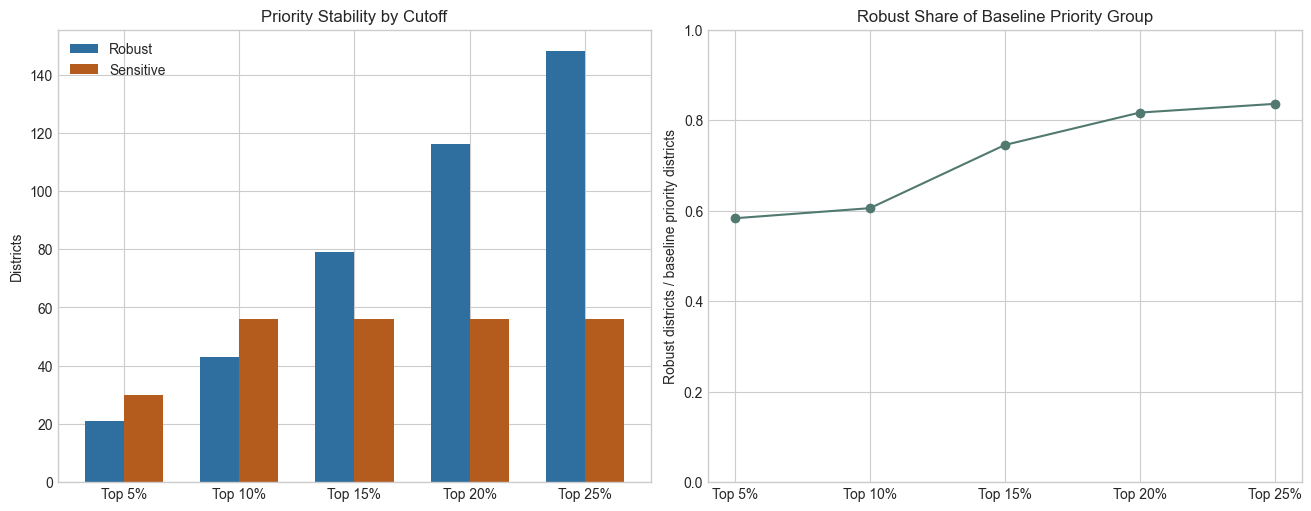

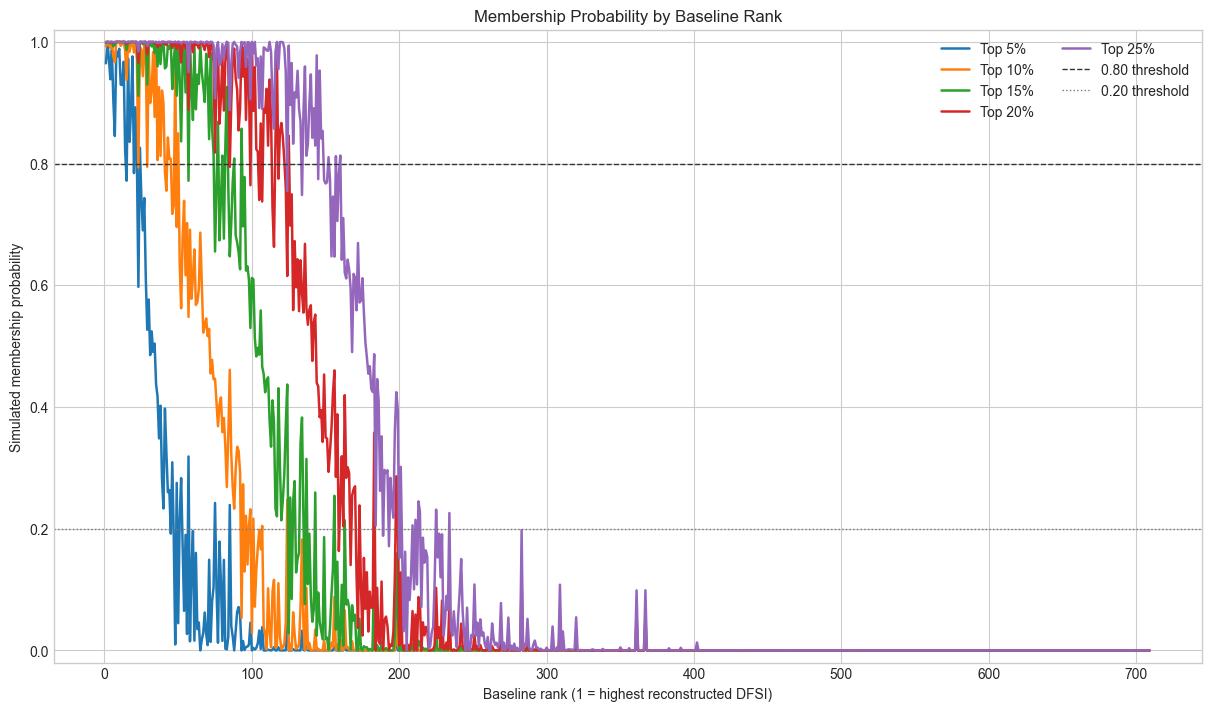

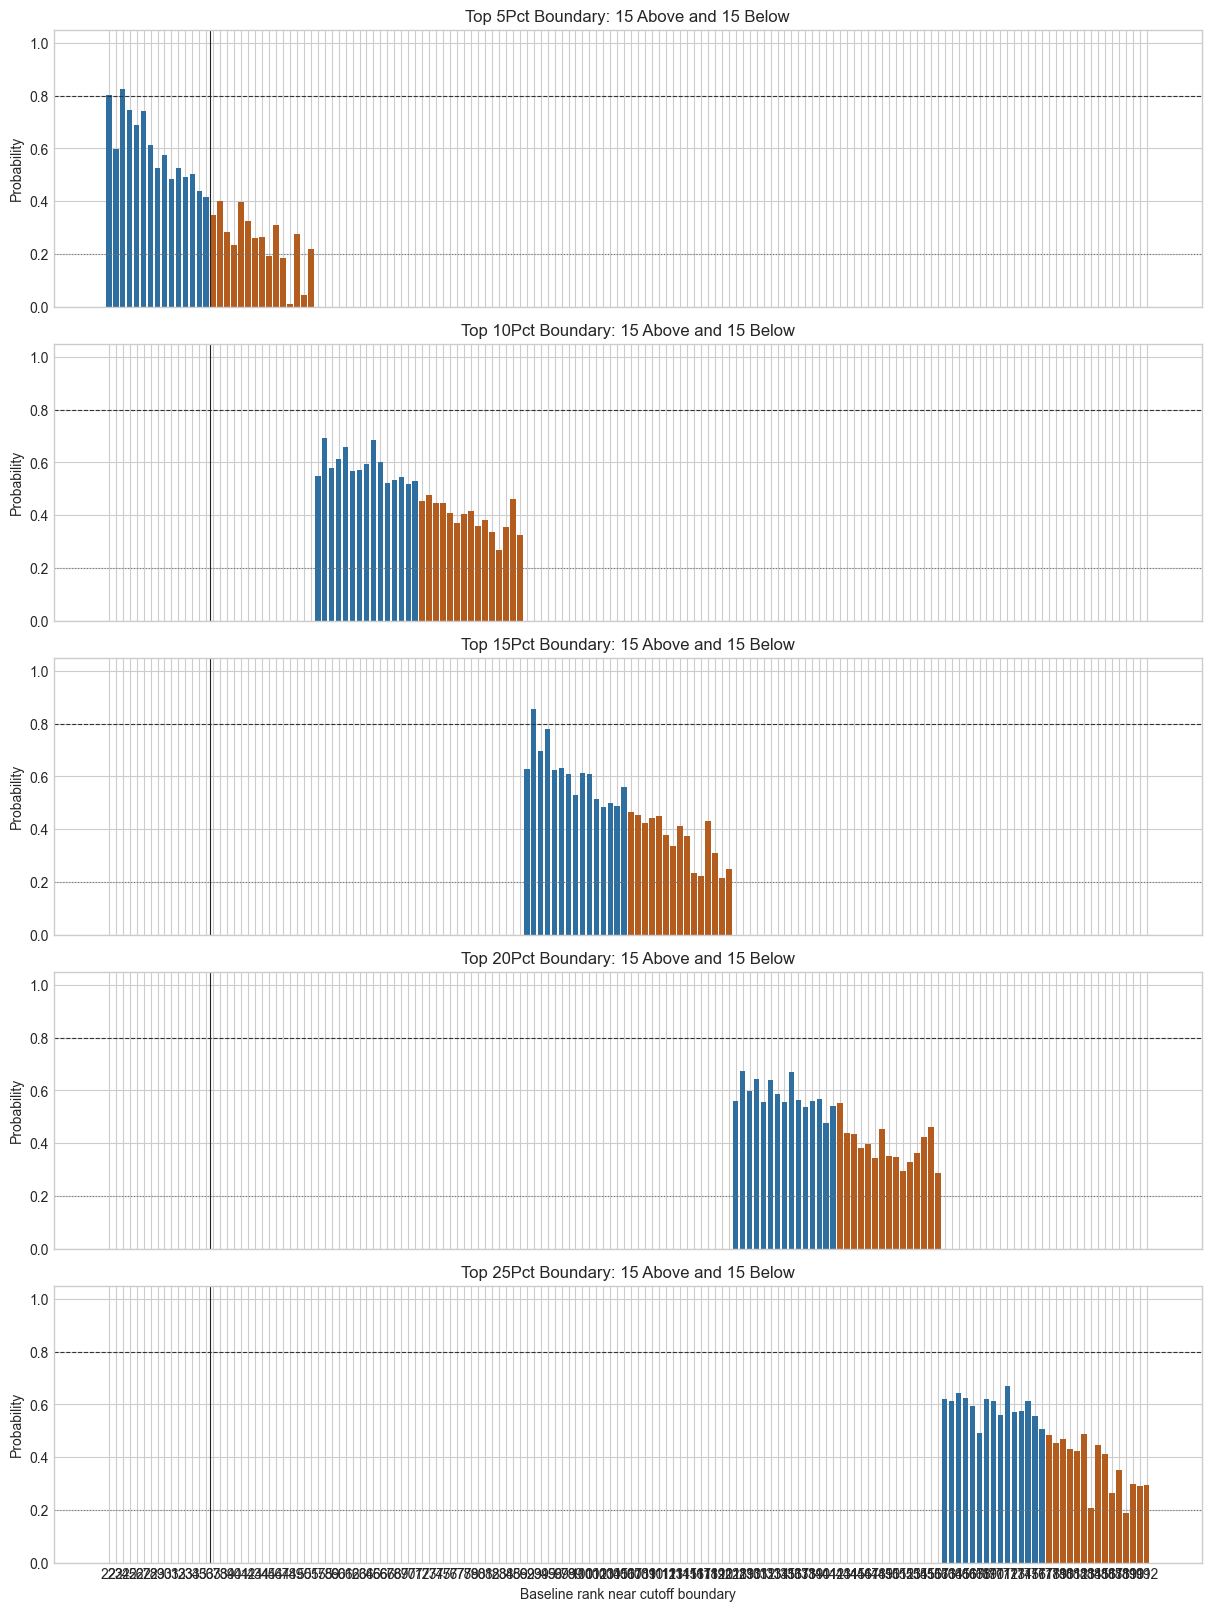

In [10]:
plt.style.use("seaborn-v0_8-whitegrid")

plot_summary = cutoff_summary.copy()
plot_summary["cutoff_label"] = plot_summary["cutoff"].map({
    "top_5pct": "Top 5%",
    "top_10pct": "Top 10%",
    "top_15pct": "Top 15%",
    "top_20pct": "Top 20%",
    "top_25pct": "Top 25%",
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
x = np.arange(len(plot_summary))
width = 0.34
axes[0].bar(x - width / 2, plot_summary["robust_priority_districts"], width=width, label="Robust", color="#2f6f9f")
axes[0].bar(x + width / 2, plot_summary["cutoff_sensitive_districts"], width=width, label="Sensitive", color="#b35c1e")
axes[0].set_xticks(x)
axes[0].set_xticklabels(plot_summary["cutoff_label"])
axes[0].set_ylabel("Districts")
axes[0].set_title("Priority Stability by Cutoff")
axes[0].legend()
axes[1].plot(plot_summary["cutoff_label"], plot_summary["baseline_priority_robust_proportion"], marker="o", color="#52796f")
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Robust districts / baseline priority districts")
axes[1].set_title("Robust Share of Baseline Priority Group")
summary_fig = FIGURE_DIR / "dfsi_cutoff_sensitivity_summary.png"
fig.savefig(summary_fig, dpi=200, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(12, 7), constrained_layout=True)
for cutoff_name, label in [
    ("top_5pct", "Top 5%"),
    ("top_10pct", "Top 10%"),
    ("top_15pct", "Top 15%"),
    ("top_20pct", "Top 20%"),
    ("top_25pct", "Top 25%"),
]:
    frame = cutoff_by_district.query("cutoff == @cutoff_name").sort_values("baseline_rank")
    ax.plot(frame["baseline_rank"], frame["simulated_membership_probability"], label=label, linewidth=1.8)
ax.axhline(0.80, color="#333333", linestyle="--", linewidth=1, label="0.80 threshold")
ax.axhline(0.20, color="#777777", linestyle=":", linewidth=1, label="0.20 threshold")
ax.set_xlabel("Baseline rank (1 = highest reconstructed DFSI)")
ax.set_ylabel("Simulated membership probability")
ax.set_title("Membership Probability by Baseline Rank")
ax.set_ylim(-0.02, 1.02)
ax.legend(ncol=2)
probability_rank_fig = FIGURE_DIR / "dfsi_membership_probability_by_baseline_rank.png"
fig.savefig(probability_rank_fig, dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(len(CUT_OFFS), 1, figsize=(12, 16), sharex=True, constrained_layout=True)
for ax, (cutoff_name, cutoff_n) in zip(axes, CUT_OFFS.items()):
    frame = boundary_districts.query("cutoff == @cutoff_name").sort_values("baseline_rank")
    colors = np.where(frame["boundary_side"].eq("immediately_above_cutoff"), "#2f6f9f", "#b35c1e")
    ax.bar(frame["baseline_rank"].astype(int).astype(str), frame["simulated_membership_probability"], color=colors)
    ax.axhline(0.80, color="#333333", linestyle="--", linewidth=0.8)
    ax.axhline(0.20, color="#777777", linestyle=":", linewidth=0.8)
    ax.axvline(14.5, color="#222222", linewidth=0.8)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Probability")
    ax.set_title(f"{cutoff_name.replace('_', ' ').title()} Boundary: 15 Above and 15 Below")
axes[-1].set_xlabel("Baseline rank near cutoff boundary")
boundary_fig = FIGURE_DIR / "dfsi_cutoff_boundary_uncertainty.png"
fig.savefig(boundary_fig, dpi=200, bbox_inches="tight")
plt.show()

for path in [summary_fig, probability_rank_fig, boundary_fig]:
    assert path.exists() and path.stat().st_size > 0, f"Figure was not created: {path}"

## Interpretation

This section answers the requested decision questions. The answer distinguishes ordinary boundary uncertainty from broader structural sensitivity caused by alternative component weights.

In [11]:
largest_sensitive_count = int(cutoff_summary["cutoff_sensitive_districts"].max())
largest_sensitive_cutoffs = cutoff_summary.loc[
    cutoff_summary["cutoff_sensitive_districts"].eq(largest_sensitive_count), "cutoff"
].tolist()
largest_sensitive_text = ", ".join(largest_sensitive_cutoffs)
robust_share_text = "; ".join(
    f"{row.cutoff}: {row.baseline_priority_robust_proportion:.1%} ({int(row.robust_priority_districts)}/{int(row.baseline_priority_districts)})"
    for row in cutoff_summary.itertuples(index=False)
)
unexpected_counts_map = unexpected_uncertainty.groupby("cutoff").size().to_dict()
nonboundary_uncertainty_count = int(len(unexpected_uncertainty))
substantial_all = bool((cutoff_summary["cutoff_sensitive_districts"] > 0).all() and (cutoff_summary["baseline_members_below_0_80_probability"] > 0).all())

print("Concise priority-cutoff interpretation")
print(f"A. Does substantial priority instability persist across all five cutoffs? {'Yes' if substantial_all else 'No'}.")
print(
    "   Every cutoff has baseline priority districts below the 0.80 reporting threshold and a nonzero set of cutoff-sensitive districts."
)
print(
    f"B. Largest number of weight-sensitive districts: {largest_sensitive_count}, "
    f"observed at {largest_sensitive_text}."
)
print(f"C. Robust proportion of baseline priority districts: {robust_share_text}.")
print(
    "D. Is uncertainty confined mainly to districts near the cutoff boundary? "
    f"No. Boundary uncertainty is visible, but {nonboundary_uncertainty_count} district-cutoff cases are sensitive despite being more than 25 ranks from the boundary."
)
print(
    "E. Are there districts far from the boundary that remain highly uncertain? "
    f"Yes. Unexpected uncertainty counts by cutoff are {unexpected_counts_map}."
)
print(
    "F. Does the paper's main conclusion depend on using the top-10% threshold? No. "
    "The instability conclusion persists across the top 5%, 10%, 15%, 20% and 25% thresholds."
)

answer_records = [
    {"question": "A", "answer": "Yes; priority instability persists across all five cutoffs." if substantial_all else "No; instability does not appear at every cutoff."},
    {"question": "B", "answer": f"{largest_sensitive_count} sensitive districts, observed at {largest_sensitive_text}."},
    {"question": "C", "answer": robust_share_text},
    {"question": "D", "answer": f"No; not confined to the boundary. {nonboundary_uncertainty_count} district-cutoff cases are sensitive more than 25 ranks from the boundary."},
    {"question": "E", "answer": f"Yes; unexpected uncertainty counts by cutoff: {unexpected_counts_map}."},
    {"question": "F", "answer": "No; the main robustness conclusion does not depend on the top-10% threshold."},
]
display(pd.DataFrame(answer_records))

Concise priority-cutoff interpretation
A. Does substantial priority instability persist across all five cutoffs? Yes.
   Every cutoff has baseline priority districts below the 0.80 reporting threshold and a nonzero set of cutoff-sensitive districts.
B. Largest number of weight-sensitive districts: 56, observed at top_10pct, top_15pct, top_20pct, top_25pct.
C. Robust proportion of baseline priority districts: top_5pct: 58.3% (21/36); top_10pct: 60.6% (43/71); top_15pct: 74.5% (79/106); top_20pct: 81.7% (116/142); top_25pct: 83.6% (148/177).
D. Is uncertainty confined mainly to districts near the cutoff boundary? No. Boundary uncertainty is visible, but 49 district-cutoff cases are sensitive despite being more than 25 ranks from the boundary.
E. Are there districts far from the boundary that remain highly uncertain? Yes. Unexpected uncertainty counts by cutoff are {'top_10pct': 9, 'top_15pct': 13, 'top_20pct': 13, 'top_25pct': 12, 'top_5pct': 2}.
F. Does the paper's main conclusion depen

,question,answer
0,A,Yes; priority instability persists across all ...
1,B,"56 sensitive districts, observed at top_10pct,..."
2,C,top_5pct: 58.3% (21/36); top_10pct: 60.6% (43/...
3,D,No; not confined to the boundary. 49 district-...
4,E,Yes; unexpected uncertainty counts by cutoff: ...
5,F,No; the main robustness conclusion does not de...


## Output Manifest

The following files were created by this notebook.

In [12]:
output_paths = [
    TABLE_DIR / "dfsi_cutoff_sensitivity_by_district.csv",
    TABLE_DIR / "dfsi_cutoff_sensitivity_summary.csv",
    TABLE_DIR / "dfsi_cutoff_boundary_districts.csv",
    TABLE_DIR / "dfsi_cutoff_unexpected_uncertainty.csv",
    FIGURE_DIR / "dfsi_cutoff_sensitivity_summary.png",
    FIGURE_DIR / "dfsi_membership_probability_by_baseline_rank.png",
    FIGURE_DIR / "dfsi_cutoff_boundary_uncertainty.png",
]
for path in output_paths:
    assert path.exists() and path.stat().st_size > 0, f"Missing expected output: {path}"
    print(f"- {path.relative_to(PROJECT_ROOT)} ({path.stat().st_size:,} bytes)")

- outputs/tables/dfsi_cutoff_sensitivity_by_district.csv (609,178 bytes)
- outputs/tables/dfsi_cutoff_sensitivity_summary.csv (954 bytes)
- outputs/tables/dfsi_cutoff_boundary_districts.csv (30,636 bytes)
- outputs/tables/dfsi_cutoff_unexpected_uncertainty.csv (11,513 bytes)
- outputs/figures/dfsi_cutoff_sensitivity_summary.png (85,557 bytes)
- outputs/figures/dfsi_membership_probability_by_baseline_rank.png (298,104 bytes)
- outputs/figures/dfsi_cutoff_boundary_uncertainty.png (227,413 bytes)
